# RQ1 — Site Effect vs. Real ASD Signal

**Question:** Do scanner/site differences inflate the apparent brain differences between ASD and controls?  
Which brain regions show a genuine ASD signal after removing site effects?

**Pipeline overview:**
1. Load & verify data (`df_clean`)
2. Visualise site effects (before harmonisation)
3. Quantify site effect — ICC
4. Quantify site effect — Eta-squared
5. ComBat harmonisation → produce `df_harmonised`
6. Cohen's d before vs after ComBat
7. Model A — naive OLS (no site control, `df_clean`)
8. Model B1 — OLS on harmonised data (`df_harmonised`)
9. Model B2 — Mixed-effects LMM (`df_clean` + site as random effect)
10. Compare three models
11. FDR correction (Benjamini-Hochberg)
12. Final summary table + visualisations

## Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
import pingouin as pg
import warnings
warnings.filterwarnings('ignore')

# Install neuroCombat if not already available
try:
    from neuroCombat import neuroCombat
except ImportError:
    import subprocess
    subprocess.run(['pip', 'install', 'neuroCombat'], capture_output=True)
    from neuroCombat import neuroCombat

print('All imports successful.')

All imports successful.


---
## BLOCK 0 — Load & Verify Data

In [2]:
# Load the cleaned dataset produced in Steps 1-2
df_clean = pd.read_csv('abide_solution_A.csv')

# Replace any remaining -9999 sentinel values with NaN
df_clean.replace(-9999, np.nan, inplace=True)

# Identify the 68 cortical thickness columns (34 lh + 34 rh)
THICKNESS_COLS = [c for c in df_clean.columns if c.startswith(('lh_', 'rh_'))]

# Ensure DX_LABEL exists; create from DX_GROUP if missing
if 'DX_LABEL' not in df_clean.columns:
    df_clean['DX_LABEL'] = df_clean['DX_GROUP'].map({1: 'ASD', 2: 'Control'})

# Basic verification
print('=== DATA OVERVIEW ===')
print(f'Shape          : {df_clean.shape}')
print(f'Thickness cols : {len(THICKNESS_COLS)}')
print(f'Sites          : {df_clean["SITE_ID"].nunique()} — {sorted(df_clean["SITE_ID"].unique())}')
print(f'ASD            : {(df_clean.DX_GROUP == 1).sum()}')
print(f'Control        : {(df_clean.DX_GROUP == 2).sum()}')
print(f'Missing thickness values: {df_clean[THICKNESS_COLS].isna().sum().sum()}')
print()
df_clean[['AGE_AT_SCAN','SEX','FIQ'] + THICKNESS_COLS[:4]].describe().round(3)

=== DATA OVERVIEW ===
Shape          : (1027, 81)
Thickness cols : 68
Sites          : 20 — ['CALTECH', 'CMU', 'KKI', 'LEUVEN_1', 'LEUVEN_2', 'MAX_MUN', 'NYU', 'OHSU', 'OLIN', 'PITT', 'SBL', 'SDSU', 'STANFORD', 'TRINITY', 'UCLA_1', 'UCLA_2', 'UM_1', 'UM_2', 'USM', 'YALE']
ASD            : 499
Control        : 528
Missing thickness values: 0



,AGE_AT_SCAN,SEX,FIQ,lh_bankssts,lh_caudalanteriorcingulate,lh_caudalmiddlefrontal,lh_cuneus
count,1027.000,1027.000,1027.000,1027.000,1027.000,1027.000,1027.000
mean,16.987,1.153,108.399,2.718,2.814,2.735,2.075
std,8.021,0.360,14.502,0.340,0.354,0.285,0.268
min,6.470,1.000,41.000,1.458,1.578,1.764,1.388
25%,11.627,1.000,100.000,2.528,2.580,2.552,1.888
50%,14.570,1.000,109.000,2.742,2.798,2.740,2.059
75%,20.000,1.000,118.000,2.960,3.028,2.935,2.239
max,64.000,2.000,148.000,3.547,4.149,3.562,2.977


---
## BLOCK 1 — Visualise Site Effects (before harmonisation)

**Input:** `df_clean`  
**Goal:** Show that different sites measure systematically different thickness values —  
this is hardware artifact, not biology.

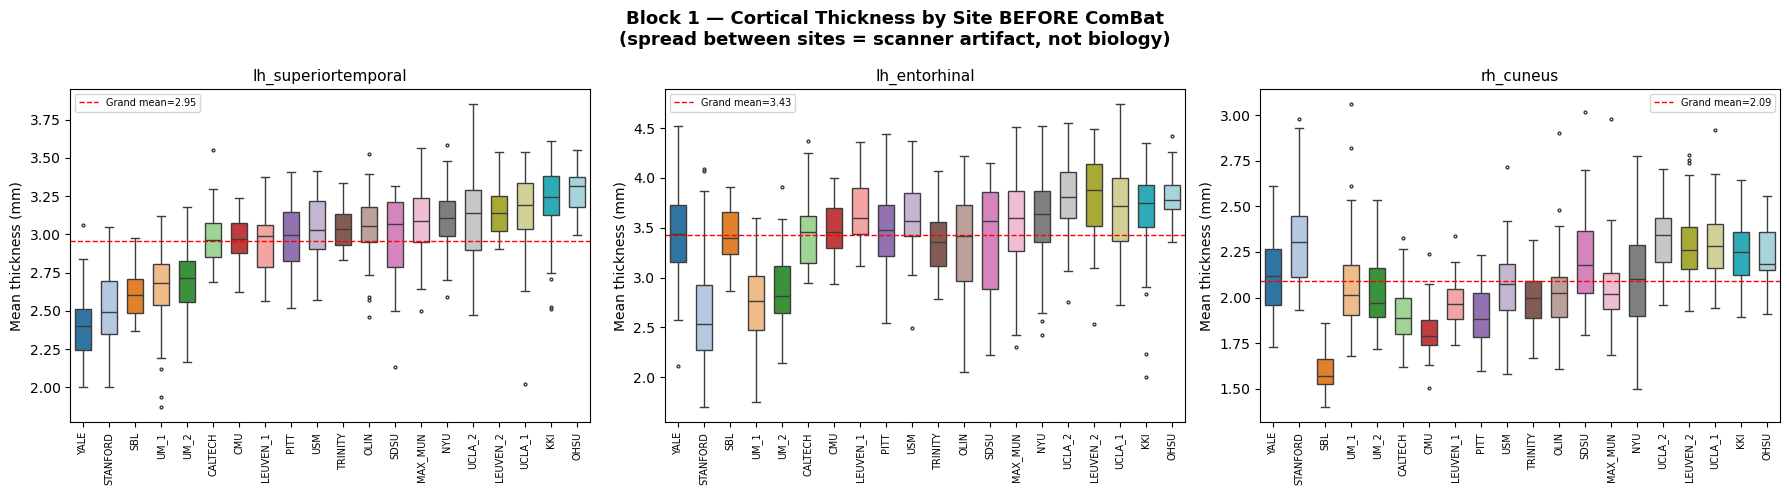

Block 1 complete. Observe the spread across sites — this motivates harmonisation.


In [3]:
# Three representative regions that typically show strong site effects
DEMO_REGIONS = ['lh_superiortemporal', 'lh_entorhinal', 'rh_cuneus']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Block 1 — Cortical Thickness by Site BEFORE ComBat\n'
             '(spread between sites = scanner artifact, not biology)',
             fontsize=13, fontweight='bold')

site_order = df_clean.groupby('SITE_ID')['lh_superiortemporal'].median().sort_values().index.tolist()

for ax, region in zip(axes, DEMO_REGIONS):
    sns.boxplot(data=df_clean, x='SITE_ID', y=region,
                order=site_order, palette='tab20',
                width=0.6, fliersize=2, ax=ax)
    ax.set_title(region, fontsize=11)
    ax.set_xlabel('')
    ax.set_ylabel('Mean thickness (mm)')
    ax.tick_params(axis='x', rotation=90, labelsize=7)
    # Add horizontal line at grand mean
    grand_mean = df_clean[region].mean()
    ax.axhline(grand_mean, color='red', linestyle='--', linewidth=1, label=f'Grand mean={grand_mean:.2f}')
    ax.legend(fontsize=7)

plt.tight_layout()
plt.savefig('block1_site_effect_before_combat.png', dpi=120, bbox_inches='tight')
plt.show()
print('Block 1 complete. Observe the spread across sites — this motivates harmonisation.')

---
## BLOCK 2 — Quantify Site Effect: ICC

**Input:** `df_clean`  
**ICC(2,1):** What fraction of variance in each region is attributable to site rather than individual biology?  
- ICC < 0.10 → site effect negligible  
- 0.10–0.30 → moderate site effect  
- ICC > 0.30 → large site effect — harmonisation essential

In [4]:
print('Computing ICC(1) for all 68 regions using one-way random effects ANOVA...')

# ICC(1) — One-way random effects model
# Each subject is measured at exactly one site (nested design, NOT repeated measures).
# pingouin.intraclass_corr() requires the same subject to appear under multiple raters,
# which does NOT apply to ABIDE. We therefore compute ICC(1) manually via ANOVA components.
# Formula: ICC(1) = (MS_between - MS_within) / (MS_between + (n0-1)*MS_within)
# where n0 = harmonic mean of group sizes (subjects per site).

def icc_oneway(series, groups):
    """One-way random effects ICC(1) with 95% CI (Shrout & Fleiss 1979)."""
    data = pd.DataFrame({'y': series, 'g': groups}).dropna()
    grand_mean  = data['y'].mean()
    N           = len(data)
    group_sizes = data.groupby('g')['y'].count()
    k           = len(group_sizes)
    # Harmonic-mean group size (corrects for unequal site sizes)
    n0 = (N - (group_sizes**2).sum() / N) / (k - 1)

    group_means = data.groupby('g')['y'].mean()
    ss_between  = sum(group_sizes[g] * (group_means[g] - grand_mean)**2 for g in group_means.index)
    ss_within   = sum(((data[data.g == g]['y'] - group_means[g])**2).sum() for g in group_means.index)

    df_between = k - 1
    df_within  = N - k
    ms_between = ss_between / df_between
    ms_within  = ss_within  / df_within

    F = ms_between / ms_within if ms_within > 0 else np.nan
    p = 1 - stats.f.cdf(F, df_between, df_within) if not np.isnan(F) else np.nan

    icc    = (ms_between - ms_within) / (ms_between + (n0 - 1) * ms_within)
    icc    = float(np.clip(icc, 0.0, 1.0))

    alpha  = 0.05
    F_lo   = F / stats.f.ppf(1 - alpha/2, df_between, df_within)
    F_hi   = F / stats.f.ppf(    alpha/2, df_between, df_within)
    ci_lo  = float(np.clip((F_lo - 1) / (F_lo + n0 - 1), 0.0, 1.0))
    ci_hi  = float(np.clip((F_hi - 1) / (F_hi + n0 - 1), 0.0, 1.0))

    return icc, ci_lo, ci_hi, F, p


icc_results = []
for col in THICKNESS_COLS:
    icc, ci_lo, ci_hi, F, p = icc_oneway(df_clean[col], df_clean['SITE_ID'])
    icc_results.append({
        'region'  : col,
        'ICC'     : icc,
        'CI_low'  : ci_lo,
        'CI_high' : ci_hi,
        'F'       : F,
        'pval_ICC': p
    })

df_icc = pd.DataFrame(icc_results).sort_values('ICC', ascending=False).reset_index(drop=True)


Computing ICC(1) for all 68 regions using one-way random effects ANOVA...


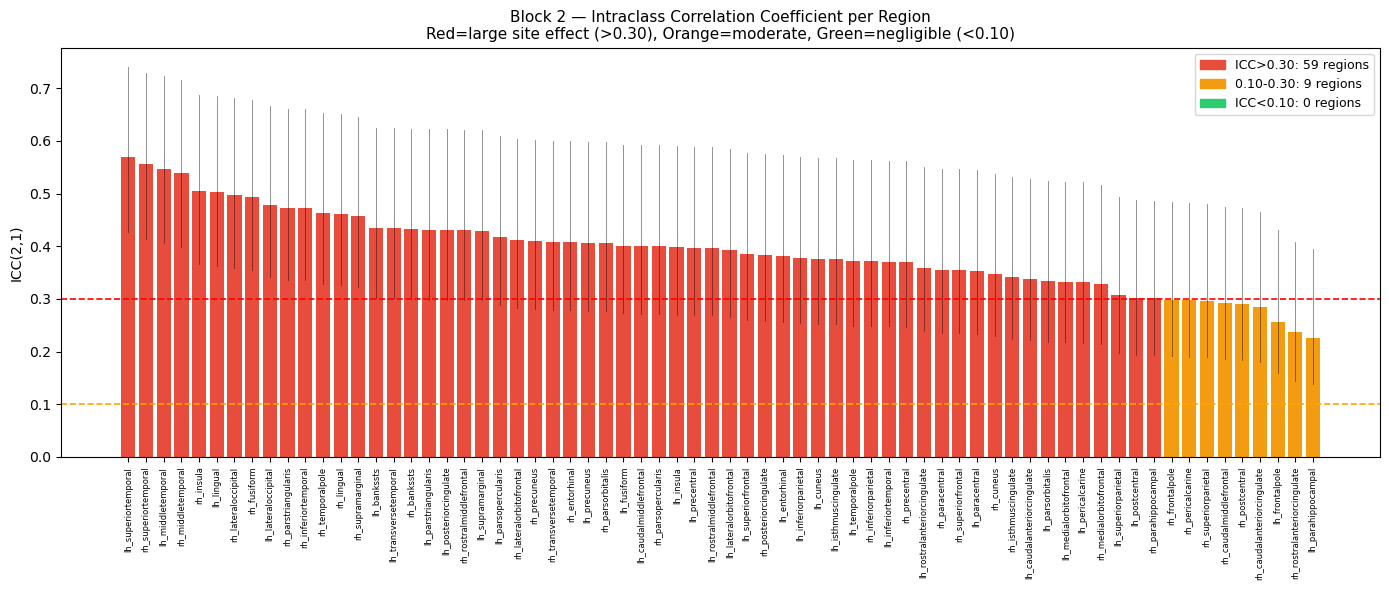

Block 2 complete.


In [5]:
# Visualise ICC for all 68 regions
def icc_color(val):
    if val > 0.30: return '#e74c3c'   # red — large
    elif val >= 0.10: return '#f39c12' # orange — moderate
    else: return '#2ecc71'             # green — negligible

colors = df_icc['ICC'].apply(icc_color)

fig, ax = plt.subplots(figsize=(14, 6))
bars = ax.bar(range(len(df_icc)), df_icc['ICC'], color=colors, edgecolor='none')

# Confidence interval lines
for i, row in df_icc.iterrows():
    ax.plot([i, i], [row['CI_low'], row['CI_high']], color='black', linewidth=0.6, alpha=0.5)

ax.axhline(0.30, color='red', linestyle='--', linewidth=1.2, label='ICC=0.30 threshold')
ax.axhline(0.10, color='orange', linestyle='--', linewidth=1.2, label='ICC=0.10 threshold')

ax.set_xticks(range(len(df_icc)))
ax.set_xticklabels(df_icc['region'], rotation=90, fontsize=6)
ax.set_ylabel('ICC(2,1)')
ax.set_title('Block 2 — Intraclass Correlation Coefficient per Region\n'
             'Red=large site effect (>0.30), Orange=moderate, Green=negligible (<0.10)',
             fontsize=11)

patches = [
    mpatches.Patch(color='#e74c3c', label=f'ICC>0.30: {(df_icc.ICC>0.30).sum()} regions'),
    mpatches.Patch(color='#f39c12', label=f'0.10-0.30: {((df_icc.ICC>=0.10)&(df_icc.ICC<=0.30)).sum()} regions'),
    mpatches.Patch(color='#2ecc71', label=f'ICC<0.10: {(df_icc.ICC<0.10).sum()} regions')
]
ax.legend(handles=patches, fontsize=9)

plt.tight_layout()
plt.savefig('block2_icc_all_regions.png', dpi=120, bbox_inches='tight')
plt.show()
print('Block 2 complete.')

---
## BLOCK 3 — Quantify Site Effect: Eta-squared

**Input:** `df_clean`  
**One-way ANOVA per region:** `thickness ~ SITE_ID`  
**η² = SS_between / SS_total** → proportion of total variance explained by site  
ICC and η² should tell the same story (high correlation between them = our measurement is consistent)

In [6]:
eta2_results = []

for col in THICKNESS_COLS:
    sub = df_clean[['SITE_ID', col]].dropna()
    groups = [grp[col].values for _, grp in sub.groupby('SITE_ID')]

    f_stat, p_val = stats.f_oneway(*groups)

    grand_mean = sub[col].mean()
    ss_total   = ((sub[col] - grand_mean) ** 2).sum()
    ss_between = sum(len(g) * (g.mean() - grand_mean) ** 2 for g in groups)
    eta2       = ss_between / ss_total

    eta2_results.append({
        'region': col,
        'F_anova': f_stat,
        'p_anova': p_val,
        'eta2': eta2
    })

df_eta = pd.DataFrame(eta2_results).sort_values('eta2', ascending=False).reset_index(drop=True)

print('=== ETA-SQUARED SUMMARY ===')
print(f'Regions with η² > 0.14 (large effect)   : {(df_eta.eta2 > 0.14).sum()}')
print(f'Regions with η² 0.06-0.14 (medium)      : {((df_eta.eta2 >= 0.06) & (df_eta.eta2 <= 0.14)).sum()}')
print(f'Regions with η² < 0.06 (small)           : {(df_eta.eta2 < 0.06).sum()}')
print(f'Mean η² across all regions               : {df_eta.eta2.mean():.3f}')
print()
print('Top 10 regions by η² (site explains most variance):')
print(df_eta.head(10)[['region','F_anova','p_anova','eta2']].round(4).to_string(index=False))

=== ETA-SQUARED SUMMARY ===
Regions with η² > 0.14 (large effect)   : 68
Regions with η² 0.06-0.14 (medium)      : 0
Regions with η² < 0.06 (small)           : 0
Mean η² across all regions               : 0.386

Top 10 regions by η² (site explains most variance):
             region  F_anova  p_anova   eta2
lh_superiortemporal  67.1724      0.0 0.5590
rh_superiortemporal  63.6993      0.0 0.5458
  lh_middletemporal  61.5229      0.0 0.5372
  rh_middletemporal  59.6760      0.0 0.5296
          rh_insula  52.1490      0.0 0.4960
         lh_lingual  51.6107      0.0 0.4934
rh_lateraloccipital  50.6752      0.0 0.4888
        rh_fusiform  49.8837      0.0 0.4849
lh_lateraloccipital  47.0716      0.0 0.4704
rh_parstriangularis  46.0029      0.0 0.4647


Pearson r between ICC and η²: 1.000  (p=1.09e-142)
If r > 0.90 → our two site-effect metrics are consistent.


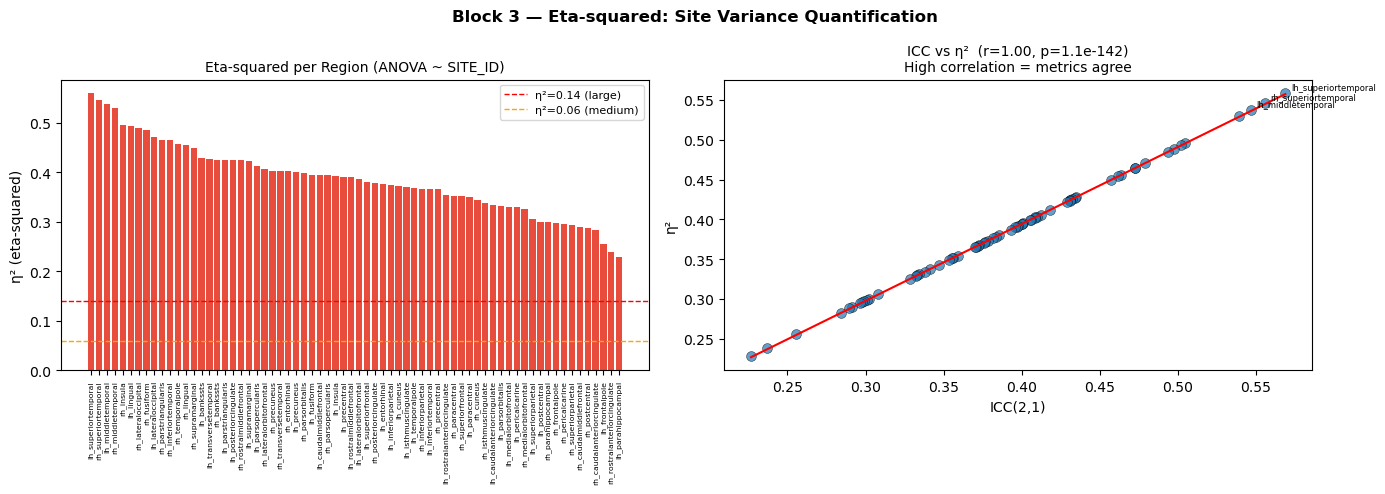

Block 3 complete.


In [7]:
# Merge ICC and eta2 to check consistency
df_site_metrics = df_icc[['region','ICC']].merge(df_eta[['region','eta2']], on='region')

r, p = stats.pearsonr(df_site_metrics['ICC'], df_site_metrics['eta2'])
print(f'Pearson r between ICC and η²: {r:.3f}  (p={p:.2e})')
print('If r > 0.90 → our two site-effect metrics are consistent.')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: eta2 bar chart
axes[0].bar(range(len(df_eta)), df_eta['eta2'],
            color=df_eta['eta2'].apply(
                lambda x: '#e74c3c' if x > 0.14 else ('#f39c12' if x >= 0.06 else '#2ecc71')),
            edgecolor='none')
axes[0].axhline(0.14, color='red', linestyle='--', linewidth=1, label='η²=0.14 (large)')
axes[0].axhline(0.06, color='orange', linestyle='--', linewidth=1, label='η²=0.06 (medium)')
axes[0].set_xticks(range(len(df_eta)))
axes[0].set_xticklabels(df_eta['region'], rotation=90, fontsize=5.5)
axes[0].set_ylabel('η² (eta-squared)')
axes[0].set_title('Eta-squared per Region (ANOVA ~ SITE_ID)', fontsize=10)
axes[0].legend(fontsize=8)

# Right: ICC vs eta2 scatter
axes[1].scatter(df_site_metrics['ICC'], df_site_metrics['eta2'],
                alpha=0.7, edgecolors='black', linewidth=0.4, s=50)
# Regression line
m, b = np.polyfit(df_site_metrics['ICC'], df_site_metrics['eta2'], 1)
x_line = np.linspace(df_site_metrics['ICC'].min(), df_site_metrics['ICC'].max(), 100)
axes[1].plot(x_line, m*x_line + b, 'r-', linewidth=1.5)
axes[1].set_xlabel('ICC(2,1)')
axes[1].set_ylabel('η²')
axes[1].set_title(f'ICC vs η²  (r={r:.2f}, p={p:.1e})\n'
                  'High correlation = metrics agree', fontsize=10)

# Annotate a few extreme points
for _, row in df_site_metrics.nlargest(3, 'ICC').iterrows():
    axes[1].annotate(row['region'], (row['ICC'], row['eta2']),
                     fontsize=6, textcoords='offset points', xytext=(4, 2))

plt.suptitle('Block 3 — Eta-squared: Site Variance Quantification', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('block3_eta2.png', dpi=120, bbox_inches='tight')
plt.show()
print('Block 3 complete.')

---
## BLOCK 4 — ComBat Harmonisation → produce `df_harmonised`

**Input:** `df_clean`  
**Goal:** Remove additive and multiplicative site-specific scanner errors while  
preserving protected biological variables: DX_GROUP, AGE_AT_SCAN, SEX  
**Output:** `df_harmonised` — same shape as `df_clean`, 68 thickness cols corrected

In [8]:
# Drop rows with any missing thickness value before ComBat
# (neuroCombat cannot handle NaN in the data matrix)
df_combat_input = df_clean.dropna(subset=THICKNESS_COLS).copy().reset_index(drop=True)
print(f'Rows used for ComBat: {len(df_combat_input)} (dropped {len(df_clean) - len(df_combat_input)} with missing thickness)')

# ComBat expects: data matrix shape (features x subjects)
data_matrix = df_combat_input[THICKNESS_COLS].T.values  # (68, N)

# Covariate dataframe — must contain batch_col and biological covariates
covars = df_combat_input[['SITE_ID', 'DX_GROUP', 'AGE_AT_SCAN', 'SEX']].copy()

print('Running ComBat harmonisation...')
combat_output = neuroCombat(
    dat=data_matrix,
    covars=covars,
    batch_col='SITE_ID',
    categorical_cols=['DX_GROUP', 'SEX'],
    continuous_cols=['AGE_AT_SCAN']
)

# Place harmonised values back into a copy of the input dataframe
df_harmonised = df_combat_input.copy()
df_harmonised[THICKNESS_COLS] = combat_output['data'].T

print('ComBat complete.')
print(f'df_harmonised shape : {df_harmonised.shape}')
print(f'ASD  : {(df_harmonised.DX_GROUP==1).sum()}')
print(f'Control : {(df_harmonised.DX_GROUP==2).sum()}')

# Sanity check: mean thickness before vs after ComBat
mean_before = df_combat_input[THICKNESS_COLS].mean().mean()
mean_after  = df_harmonised[THICKNESS_COLS].mean().mean()
print(f'\nGlobal mean thickness — before: {mean_before:.4f} mm  after: {mean_after:.4f} mm')
print('(Values should be very close — ComBat preserves the group mean)')

Rows used for ComBat: 1027 (dropped 0 with missing thickness)
Running ComBat harmonisation...
[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
ComBat complete.
df_harmonised shape : (1027, 81)
ASD  : 499
Control : 528

Global mean thickness — before: 2.7577 mm  after: 2.7576 mm
(Values should be very close — ComBat preserves the group mean)


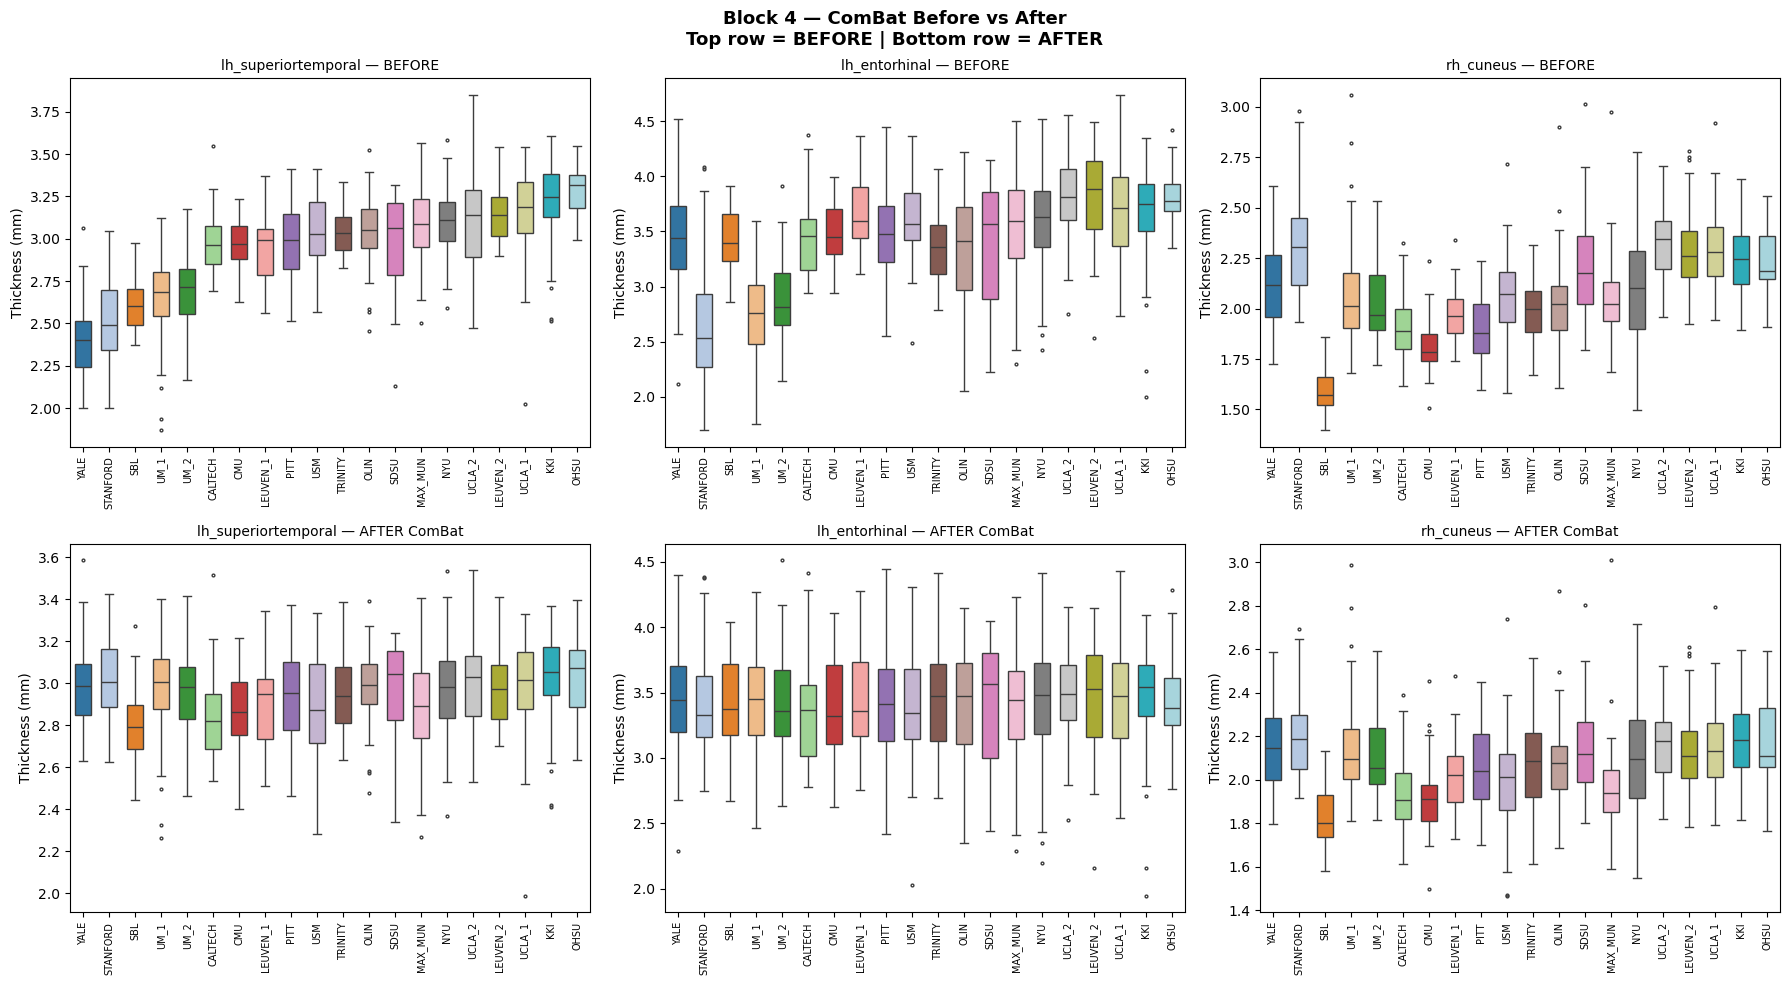

Block 4 complete. After ComBat, site medians should align.


In [9]:
# Before vs After ComBat boxplots for the same 3 demo regions
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Block 4 — ComBat Before vs After\nTop row = BEFORE | Bottom row = AFTER',
             fontsize=13, fontweight='bold')

for col_idx, region in enumerate(DEMO_REGIONS):
    # Before (df_combat_input)
    sns.boxplot(data=df_combat_input, x='SITE_ID', y=region,
                order=site_order, palette='tab20', width=0.6, fliersize=2,
                ax=axes[0, col_idx])
    axes[0, col_idx].set_title(f'{region} — BEFORE', fontsize=10)
    axes[0, col_idx].tick_params(axis='x', rotation=90, labelsize=7)
    axes[0, col_idx].set_xlabel('')
    axes[0, col_idx].set_ylabel('Thickness (mm)')

    # After (df_harmonised)
    sns.boxplot(data=df_harmonised, x='SITE_ID', y=region,
                order=site_order, palette='tab20', width=0.6, fliersize=2,
                ax=axes[1, col_idx])
    axes[1, col_idx].set_title(f'{region} — AFTER ComBat', fontsize=10)
    axes[1, col_idx].tick_params(axis='x', rotation=90, labelsize=7)
    axes[1, col_idx].set_xlabel('')
    axes[1, col_idx].set_ylabel('Thickness (mm)')

plt.tight_layout()
plt.savefig('block4_combat_before_after.png', dpi=120, bbox_inches='tight')
plt.show()
print('Block 4 complete. After ComBat, site medians should align.')

---
## BLOCK 5 — Cohen's d Before vs After ComBat

**Input:** `df_combat_input` (before) + `df_harmonised` (after)  
**Goal:** For each region, measure ASD vs Control effect size twice.  
- Large Δd → the apparent ASD difference was mostly scanner artifact  
- Small Δd → the difference is robust biological signal

In [10]:
def cohens_d(group1, group2):
    """Pooled Cohen's d (positive = ASD > Control)."""
    n1, n2 = len(group1), len(group2)
    pooled_var = ((n1 - 1) * group1.var(ddof=1) + (n2 - 1) * group2.var(ddof=1)) / (n1 + n2 - 2)
    return (group1.mean() - group2.mean()) / np.sqrt(pooled_var)

cohens_results = []

for col in THICKNESS_COLS:
    asd_before  = df_combat_input[df_combat_input.DX_GROUP == 1][col].dropna()
    ctrl_before = df_combat_input[df_combat_input.DX_GROUP == 2][col].dropna()
    asd_after   = df_harmonised[df_harmonised.DX_GROUP == 1][col].dropna()
    ctrl_after  = df_harmonised[df_harmonised.DX_GROUP == 2][col].dropna()

    d_before = cohens_d(asd_before, ctrl_before)
    d_after  = cohens_d(asd_after,  ctrl_after)

    cohens_results.append({
        'region'  : col,
        'd_before': d_before,
        'd_after' : d_after,
        'abs_before': abs(d_before),
        'abs_after' : abs(d_after),
        'delta_d' : abs(d_before) - abs(d_after)   # positive = ComBat reduced the effect
    })

df_cohens = pd.DataFrame(cohens_results)

print('=== COHEN\'S d SUMMARY ===')
print(f'Regions where |d| decreased after ComBat : {(df_cohens.delta_d > 0).sum()} (site was inflating the effect)')
print(f'Regions where |d| increased after ComBat : {(df_cohens.delta_d < 0).sum()} (site was suppressing the effect)')
print(f'Mean |d_before| : {df_cohens.abs_before.mean():.3f}')
print(f'Mean |d_after|  : {df_cohens.abs_after.mean():.3f}')
print()
print('Top 10 regions with largest Δd (most site-contaminated):')
print(df_cohens.nlargest(10, 'delta_d')[['region','d_before','d_after','delta_d']].round(3).to_string(index=False))

=== COHEN'S d SUMMARY ===
Regions where |d| decreased after ComBat : 19 (site was inflating the effect)
Regions where |d| increased after ComBat : 49 (site was suppressing the effect)
Mean |d_before| : 0.057
Mean |d_after|  : 0.067

Top 10 regions with largest Δd (most site-contaminated):
                     region  d_before  d_after  delta_d
         rh_superiorfrontal    -0.104   -0.027    0.077
           rh_parsorbitalis    -0.054    0.015    0.039
    rh_lateralorbitofrontal    -0.045    0.006    0.038
             lh_postcentral     0.049    0.015    0.034
         lh_superiorfrontal    -0.039   -0.006    0.033
        rh_superiorparietal     0.041    0.009    0.033
         rh_parsopercularis    -0.105   -0.075    0.031
rh_rostralanteriorcingulate    -0.032   -0.004    0.027
        lh_superiorparietal     0.055    0.031    0.024
     rh_caudalmiddlefrontal    -0.136   -0.113    0.023


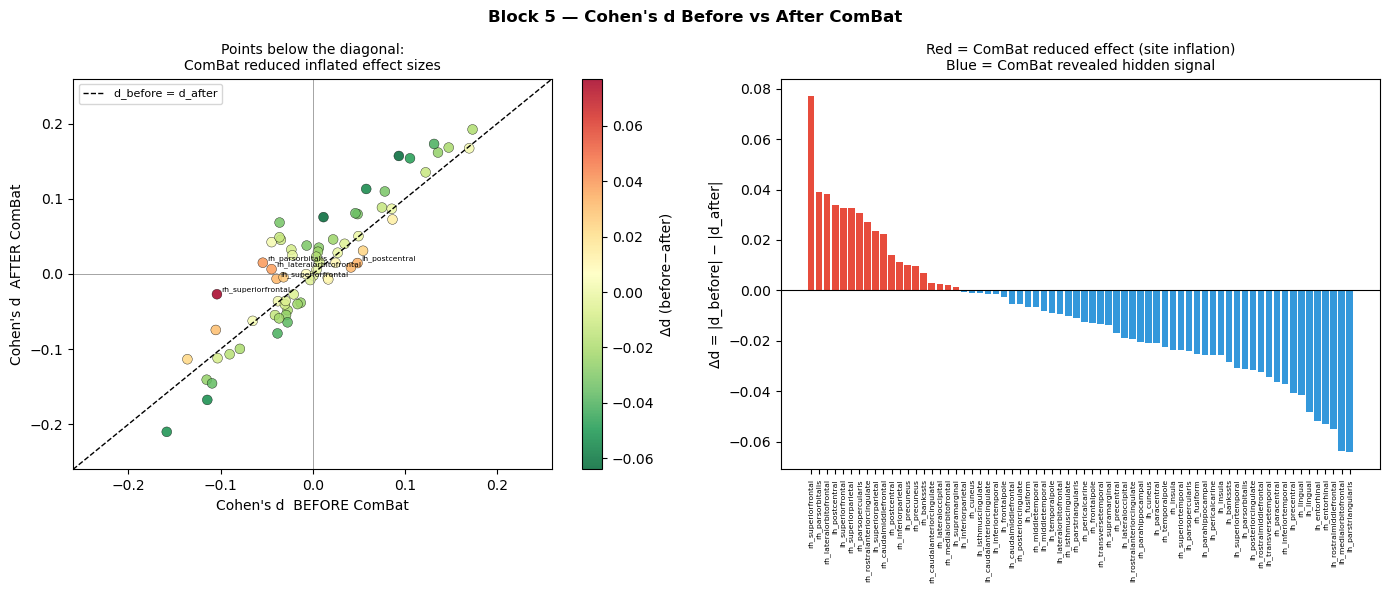

Block 5 complete.


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left: scatter d_before vs d_after
sc = axes[0].scatter(df_cohens['d_before'], df_cohens['d_after'],
                     c=df_cohens['delta_d'], cmap='RdYlGn_r',
                     edgecolors='black', linewidth=0.3, s=50, alpha=0.85)
lim = max(abs(df_cohens[['d_before','d_after']].values.flatten())) + 0.05
axes[0].plot([-lim, lim], [-lim, lim], 'k--', linewidth=1, label='d_before = d_after')
axes[0].axhline(0, color='grey', linewidth=0.5)
axes[0].axvline(0, color='grey', linewidth=0.5)
axes[0].set_xlim(-lim, lim)
axes[0].set_ylim(-lim, lim)
axes[0].set_xlabel("Cohen's d  BEFORE ComBat")
axes[0].set_ylabel("Cohen's d  AFTER ComBat")
axes[0].set_title("Points below the diagonal:\nComBat reduced inflated effect sizes", fontsize=10)
axes[0].legend(fontsize=8)
plt.colorbar(sc, ax=axes[0], label='Δd (before−after)')

# Annotate top 5 most changed regions
for _, row in df_cohens.nlargest(5, 'delta_d').iterrows():
    axes[0].annotate(row['region'], (row['d_before'], row['d_after']),
                     fontsize=5.5, textcoords='offset points', xytext=(3, 2))

# Right: delta_d bar chart (sorted)
df_plot = df_cohens.sort_values('delta_d', ascending=False)
bar_colors = ['#e74c3c' if v > 0 else '#3498db' for v in df_plot['delta_d']]
axes[1].bar(range(len(df_plot)), df_plot['delta_d'], color=bar_colors, edgecolor='none')
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_xticks(range(len(df_plot)))
axes[1].set_xticklabels(df_plot['region'], rotation=90, fontsize=5.5)
axes[1].set_ylabel('Δd = |d_before| − |d_after|')
axes[1].set_title('Red = ComBat reduced effect (site inflation)\nBlue = ComBat revealed hidden signal', fontsize=10)

plt.suptitle("Block 5 — Cohen's d Before vs After ComBat", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('block5_cohens_d.png', dpi=120, bbox_inches='tight')
plt.show()
print('Block 5 complete.')

---
## BLOCK 6 — Model A: Naive Baseline OLS (no site control)

**Input:** `df_combat_input` (cleaned, but site effect still present)  
**Model:** `thickness ~ DX_GROUP + AGE_AT_SCAN + SEX`  
**Purpose:** Intentionally incorrect baseline — shows how many regions appear  
significant when site is ignored. These are potential false positives.

In [12]:
results_A = []

for col in THICKNESS_COLS:
    # Rename column to a safe name — statsmodels formula parser
    # does NOT support column names with underscores when passed via backticks
    # on all platforms. Renaming to 'y' is the safest cross-platform approach.
    tmp = df_combat_input[['DX_GROUP', 'AGE_AT_SCAN', 'SEX', col]].copy()
    tmp = tmp.rename(columns={col: 'y'})
    try:
        fit = smf.ols('y ~ DX_GROUP + AGE_AT_SCAN + SEX', data=tmp).fit()
        results_A.append({
            'region' : col,
            'beta_A' : fit.params['DX_GROUP'],
            'se_A'   : fit.bse['DX_GROUP'],
            'p_A'    : fit.pvalues['DX_GROUP'],
            'r2_A'   : fit.rsquared
        })
    except Exception as e:
        print(f'Model A failed for {col}: {e}')

df_modelA = pd.DataFrame(results_A)
df_modelA['sig_A'] = df_modelA['p_A'] < 0.05

n_sig_A = df_modelA['sig_A'].sum()
print('=== MODEL A RESULTS (naive, no site control) ===')
print(f'Regions significant at p<0.05 : {n_sig_A} / {len(df_modelA)}')
print(f'Proportion                     : {n_sig_A/len(df_modelA)*100:.1f}%')
print()
print('Significant regions (Model A):')
sig_A = df_modelA[df_modelA['sig_A']].sort_values('p_A')
print(sig_A[['region','beta_A','p_A']].round(4).to_string(index=False))


=== MODEL A RESULTS (naive, no site control) ===
Regions significant at p<0.05 : 11 / 68
Proportion                     : 16.2%

Significant regions (Model A):
                region  beta_A    p_A
   lh_lateraloccipital -0.0441 0.0004
   rh_lateraloccipital -0.0448 0.0008
             lh_cuneus -0.0446 0.0010
      lh_pericalcarine -0.0409 0.0032
            rh_lingual -0.0374 0.0039
         lh_entorhinal  0.0910 0.0063
      rh_pericalcarine -0.0340 0.0121
            lh_lingual -0.0306 0.0142
             rh_cuneus -0.0279 0.0404
rh_caudalmiddlefrontal  0.0297 0.0471
 lh_posteriorcingulate -0.0261 0.0481


---
## BLOCK 7 — Model B1: OLS on Harmonised Data

**Input:** `df_harmonised`  
**Model:** `thickness ~ DX_GROUP + AGE_AT_SCAN + SEX`  
ComBat already removed site variance — no need to include SITE_ID in the model.

In [13]:
results_B1 = []

for col in THICKNESS_COLS:
    tmp = df_harmonised[['DX_GROUP', 'AGE_AT_SCAN', 'SEX', col]].copy()
    tmp = tmp.rename(columns={col: 'y'})
    try:
        fit = smf.ols('y ~ DX_GROUP + AGE_AT_SCAN + SEX', data=tmp).fit()
        results_B1.append({
            'region'  : col,
            'beta_B1' : fit.params['DX_GROUP'],
            'se_B1'   : fit.bse['DX_GROUP'],
            'p_B1'    : fit.pvalues['DX_GROUP'],
            'r2_B1'   : fit.rsquared
        })
    except Exception as e:
        print(f'Model B1 failed for {col}: {e}')

df_modelB1 = pd.DataFrame(results_B1)
df_modelB1['sig_B1'] = df_modelB1['p_B1'] < 0.05

n_sig_B1 = df_modelB1['sig_B1'].sum()
print('=== MODEL B1 RESULTS (ComBat harmonised OLS) ===')
print(f'Regions significant at p<0.05 : {n_sig_B1} / {len(df_modelB1)}')
print()
print('Significant regions (Model B1):')
sig_B1 = df_modelB1[df_modelB1['sig_B1']].sort_values('p_B1')
print(sig_B1[['region','beta_B1','p_B1']].round(4).to_string(index=False))


=== MODEL B1 RESULTS (ComBat harmonised OLS) ===
Regions significant at p<0.05 : 17 / 68

Significant regions (Model B1):
                 region  beta_B1   p_B1
    lh_lateraloccipital  -0.0371 0.0002
             rh_lingual  -0.0380 0.0003
              lh_cuneus  -0.0410 0.0006
          lh_entorhinal   0.0888 0.0007
    rh_lateraloccipital  -0.0333 0.0008
             lh_lingual  -0.0327 0.0009
       lh_pericalcarine  -0.0381 0.0018
 lh_medialorbitofrontal  -0.0409 0.0020
lh_rostralmiddlefrontal  -0.0326 0.0071
          rh_entorhinal   0.0710 0.0095
       rh_pericalcarine  -0.0310 0.0108
  lh_posteriorcingulate  -0.0271 0.0183
         rh_paracentral   0.0276 0.0248
  rh_transversetemporal  -0.0334 0.0381
     lh_parahippocampal   0.0434 0.0398
              rh_cuneus  -0.0239 0.0469
    lh_parstriangularis  -0.0262 0.0495


---
## BLOCK 8 — Model B2: Mixed-Effects LMM (site as random effect)

**Input:** `df_combat_input` (uncorrected data)  
**Model:** `thickness ~ DX_GROUP + AGE_AT_SCAN + SEX + (1|SITE_ID)`  
**Purpose:** Independent approach to site control — no ComBat needed.  
If B1 and B2 agree on the same regions → findings are robust.

In [14]:
results_B2 = []

for col in THICKNESS_COLS:
    tmp = df_combat_input[['DX_GROUP', 'AGE_AT_SCAN', 'SEX', 'SITE_ID', col]].copy()
    tmp = tmp.rename(columns={col: 'y'})
    try:
        fit = smf.mixedlm(
            'y ~ DX_GROUP + AGE_AT_SCAN + SEX',
            data=tmp,
            groups=tmp['SITE_ID']
        ).fit(reml=True, method='lbfgs')
        results_B2.append({
            'region'  : col,
            'beta_B2' : fit.params['DX_GROUP'],
            'se_B2'   : fit.bse['DX_GROUP'],
            'p_B2'    : fit.pvalues['DX_GROUP']
        })
    except Exception as e:
        print(f'Model B2 failed for {col}: {e}')
        results_B2.append({'region': col, 'beta_B2': np.nan,
                            'se_B2': np.nan, 'p_B2': np.nan})

df_modelB2 = pd.DataFrame(results_B2)
df_modelB2['sig_B2'] = df_modelB2['p_B2'] < 0.05

n_sig_B2 = df_modelB2['sig_B2'].sum()
print('=== MODEL B2 RESULTS (Mixed-Effects LMM) ===')
print(f'Regions significant at p<0.05 : {n_sig_B2} / {len(df_modelB2)}')
print()
print('Significant regions (Model B2):')
sig_B2 = df_modelB2[df_modelB2['sig_B2']].sort_values('p_B2')
print(sig_B2[['region','beta_B2','p_B2']].round(4).to_string(index=False))


=== MODEL B2 RESULTS (Mixed-Effects LMM) ===
Regions significant at p<0.05 : 17 / 68

Significant regions (Model B2):
                 region  beta_B2   p_B2
    lh_lateraloccipital  -0.0380 0.0001
          lh_entorhinal   0.0977 0.0003
              lh_cuneus  -0.0435 0.0004
             rh_lingual  -0.0368 0.0006
    rh_lateraloccipital  -0.0340 0.0010
       lh_pericalcarine  -0.0409 0.0014
 lh_medialorbitofrontal  -0.0424 0.0017
             lh_lingual  -0.0309 0.0021
          rh_entorhinal   0.0791 0.0045
       rh_pericalcarine  -0.0337 0.0073
lh_rostralmiddlefrontal  -0.0320 0.0105
        lh_temporalpole   0.0597 0.0255
  rh_transversetemporal  -0.0363 0.0276
  lh_posteriorcingulate  -0.0249 0.0334
     lh_parahippocampal   0.0453 0.0342
         rh_paracentral   0.0267 0.0354
              rh_cuneus  -0.0248 0.0457


---
## BLOCK 9 — Compare Three Models

**Categorisation logic:**
- Significant in A but NOT in B1 or B2 → **False positive** (site artifact)
- Significant in A AND in B1 or B2 → **Strong ASD signal**
- NOT significant in A but significant in B → **Site-suppressed signal** (rare)
- Significant in neither → **Not significant**

In [15]:
# Merge all three model results
df_compare = (
    df_modelA[['region','p_A','beta_A','sig_A']]
    .merge(df_modelB1[['region','p_B1','beta_B1','sig_B1']], on='region')
    .merge(df_modelB2[['region','p_B2','beta_B2','sig_B2']], on='region')
)

def categorise(row):
    b_sig = row['sig_B1'] or row['sig_B2']  # significant in at least one site-controlled model
    if row['sig_A'] and not b_sig:
        return 'False positive (site artifact)'
    elif row['sig_A'] and b_sig:
        return 'Strong ASD signal'
    elif not row['sig_A'] and b_sig:
        return 'Site-suppressed signal'
    else:
        return 'Not significant'

df_compare['category'] = df_compare.apply(categorise, axis=1)

print('=== THREE-MODEL COMPARISON ===')
print(df_compare['category'].value_counts().to_string())
print()

cat_order = ['Strong ASD signal', 'False positive (site artifact)',
             'Site-suppressed signal', 'Not significant']
for cat in cat_order:
    sub = df_compare[df_compare['category'] == cat]
    if len(sub) > 0:
        print(f'--- {cat} ({len(sub)} regions) ---')
        print(sub[['region','p_A','p_B1','p_B2']].round(4).to_string(index=False))
        print()

=== THREE-MODEL COMPARISON ===
category
Not significant                   49
Strong ASD signal                 10
Site-suppressed signal             8
False positive (site artifact)     1

--- Strong ASD signal (10 regions) ---
               region    p_A   p_B1   p_B2
            lh_cuneus 0.0010 0.0006 0.0004
        lh_entorhinal 0.0063 0.0007 0.0003
  lh_lateraloccipital 0.0004 0.0002 0.0001
           lh_lingual 0.0142 0.0009 0.0021
     lh_pericalcarine 0.0032 0.0018 0.0014
lh_posteriorcingulate 0.0481 0.0183 0.0334
            rh_cuneus 0.0404 0.0469 0.0457
  rh_lateraloccipital 0.0008 0.0008 0.0010
           rh_lingual 0.0039 0.0003 0.0006
     rh_pericalcarine 0.0121 0.0108 0.0073

--- False positive (site artifact) (1 regions) ---
                region    p_A   p_B1   p_B2
rh_caudalmiddlefrontal 0.0471 0.0952 0.0705

--- Site-suppressed signal (8 regions) ---
                 region    p_A   p_B1   p_B2
 lh_medialorbitofrontal 0.0587 0.0020 0.0017
     lh_parahippocampal 0

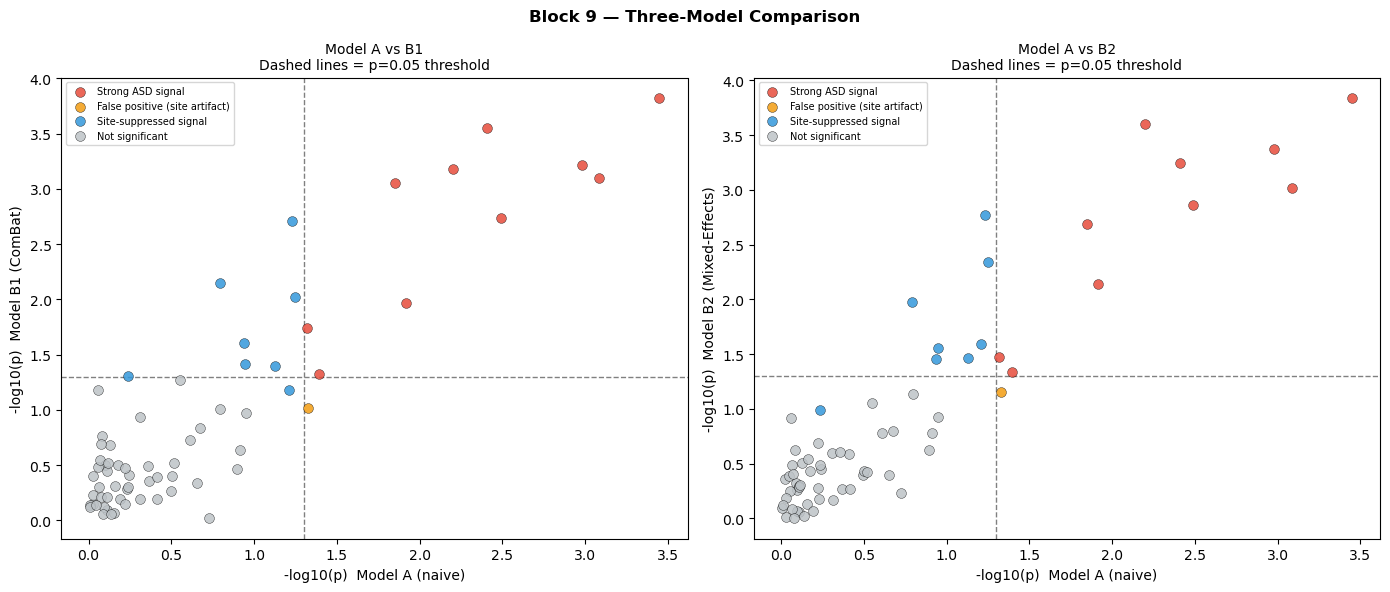

Block 9 complete.


In [16]:
# Visualise p-values: Model A vs Model B1 scatter
cat_colors = {
    'Strong ASD signal'            : '#e74c3c',
    'False positive (site artifact)': '#f39c12',
    'Site-suppressed signal'        : '#3498db',
    'Not significant'               : '#bdc3c7'
}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left: A vs B1
for cat, color in cat_colors.items():
    sub = df_compare[df_compare['category'] == cat]
    axes[0].scatter(-np.log10(sub['p_A']), -np.log10(sub['p_B1']),
                    color=color, label=cat, edgecolors='black', linewidth=0.3,
                    s=50, alpha=0.85, zorder=3)

thresh = -np.log10(0.05)
axes[0].axhline(thresh, color='grey', linestyle='--', linewidth=1)
axes[0].axvline(thresh, color='grey', linestyle='--', linewidth=1)
axes[0].set_xlabel('-log10(p)  Model A (naive)')
axes[0].set_ylabel('-log10(p)  Model B1 (ComBat)')
axes[0].set_title('Model A vs B1\nDashed lines = p=0.05 threshold', fontsize=10)
axes[0].legend(fontsize=7, loc='upper left')

# Right: A vs B2
for cat, color in cat_colors.items():
    sub = df_compare[df_compare['category'] == cat]
    axes[1].scatter(-np.log10(sub['p_A']), -np.log10(sub['p_B2'].fillna(1)),
                    color=color, label=cat, edgecolors='black', linewidth=0.3,
                    s=50, alpha=0.85, zorder=3)

axes[1].axhline(thresh, color='grey', linestyle='--', linewidth=1)
axes[1].axvline(thresh, color='grey', linestyle='--', linewidth=1)
axes[1].set_xlabel('-log10(p)  Model A (naive)')
axes[1].set_ylabel('-log10(p)  Model B2 (Mixed-Effects)')
axes[1].set_title('Model A vs B2\nDashed lines = p=0.05 threshold', fontsize=10)
axes[1].legend(fontsize=7, loc='upper left')

plt.suptitle('Block 9 — Three-Model Comparison', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('block9_model_comparison.png', dpi=120, bbox_inches='tight')
plt.show()
print('Block 9 complete.')

---
## BLOCK 10 — FDR Correction (Benjamini-Hochberg)

**Problem:** We ran 68 independent tests. By chance, ~3-4 will appear significant at p<0.05.  
**Solution:** Benjamini-Hochberg FDR controls the expected proportion of false discoveries.  
Applied to Model B1 and Model B2 separately.

In [17]:
# FDR correction for Model B1
p_B1_array = df_compare['p_B1'].fillna(1).values
_, p_B1_fdr, _, _ = multipletests(p_B1_array, method='fdr_bh')

# FDR correction for Model B2
p_B2_array = df_compare['p_B2'].fillna(1).values
_, p_B2_fdr, _, _ = multipletests(p_B2_array, method='fdr_bh')

df_compare['p_B1_fdr'] = p_B1_fdr
df_compare['p_B2_fdr'] = p_B2_fdr
df_compare['sig_B1_fdr'] = p_B1_fdr < 0.05
df_compare['sig_B2_fdr'] = p_B2_fdr < 0.05
df_compare['sig_both_fdr'] = df_compare['sig_B1_fdr'] & df_compare['sig_B2_fdr']

print('=== FDR CORRECTION RESULTS ===')
print(f'Model B1 — before FDR: {df_compare["sig_B1"].sum()} | after FDR: {df_compare["sig_B1_fdr"].sum()}')
print(f'Model B2 — before FDR: {df_compare["sig_B2"].sum()} | after FDR: {df_compare["sig_B2_fdr"].sum()}')
print(f'Confirmed by BOTH B1 and B2 after FDR: {df_compare["sig_both_fdr"].sum()}')
print()

if df_compare['sig_B1_fdr'].sum() > 0:
    print('FDR-significant in B1:')
    print(df_compare[df_compare['sig_B1_fdr']]
          [['region','p_B1','p_B1_fdr','beta_B1']].sort_values('p_B1_fdr').round(4).to_string(index=False))
    print()

if df_compare['sig_B2_fdr'].sum() > 0:
    print('FDR-significant in B2:')
    print(df_compare[df_compare['sig_B2_fdr']]
          [['region','p_B2','p_B2_fdr','beta_B2']].sort_values('p_B2_fdr').round(4).to_string(index=False))

if df_compare['sig_both_fdr'].sum() > 0:
    print('\nRegions confirmed by BOTH methods after FDR (most reliable ASD signal):')
    print(df_compare[df_compare['sig_both_fdr']]
          [['region','p_B1_fdr','p_B2_fdr','beta_B1','beta_B2']].sort_values('p_B1_fdr').round(4).to_string(index=False))

=== FDR CORRECTION RESULTS ===
Model B1 — before FDR: 17 | after FDR: 8
Model B2 — before FDR: 17 | after FDR: 10
Confirmed by BOTH B1 and B2 after FDR: 8

FDR-significant in B1:
                region   p_B1  p_B1_fdr  beta_B1
   lh_lateraloccipital 0.0002    0.0096  -0.0371
            rh_lingual 0.0003    0.0096  -0.0380
             lh_cuneus 0.0006    0.0100  -0.0410
         lh_entorhinal 0.0007    0.0100   0.0888
            lh_lingual 0.0009    0.0100  -0.0327
   rh_lateraloccipital 0.0008    0.0100  -0.0333
lh_medialorbitofrontal 0.0020    0.0166  -0.0409
      lh_pericalcarine 0.0018    0.0166  -0.0381

FDR-significant in B2:
                region   p_B2  p_B2_fdr  beta_B2
         lh_entorhinal 0.0003    0.0085   0.0977
   lh_lateraloccipital 0.0001    0.0085  -0.0380
             lh_cuneus 0.0004    0.0096  -0.0435
            rh_lingual 0.0006    0.0097  -0.0368
   rh_lateraloccipital 0.0010    0.0130  -0.0340
      lh_pericalcarine 0.0014    0.0156  -0.0409
lh_medialorbi

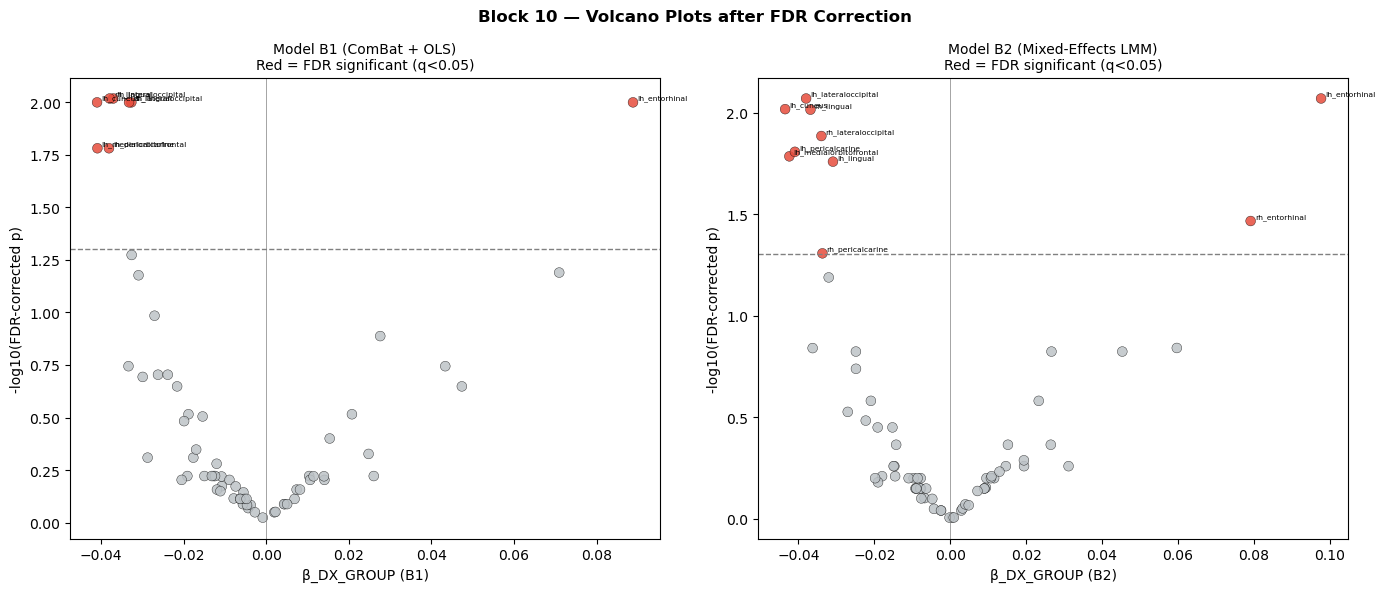

Block 10 complete.


In [18]:
# Volcano-style plot: effect size vs significance (B1 after FDR)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, model, p_raw_col, p_fdr_col, beta_col, title in [
    (axes[0], 'B1', 'p_B1', 'p_B1_fdr', 'beta_B1', 'Model B1 (ComBat + OLS)'),
    (axes[1], 'B2', 'p_B2', 'p_B2_fdr', 'beta_B2', 'Model B2 (Mixed-Effects LMM)')
]:
    sub = df_compare.copy()
    sub['neg_log_fdr'] = -np.log10(sub[p_fdr_col].fillna(1))
    sub['color'] = sub[p_fdr_col].apply(lambda p: '#e74c3c' if p < 0.05 else '#bdc3c7')

    ax.scatter(sub[beta_col], sub['neg_log_fdr'],
               c=sub['color'], edgecolors='black', linewidth=0.3, s=50, alpha=0.85)

    ax.axhline(-np.log10(0.05), color='grey', linestyle='--', linewidth=1)
    ax.axvline(0, color='grey', linewidth=0.5)
    ax.set_xlabel(f'β_DX_GROUP ({model})')
    ax.set_ylabel('-log10(FDR-corrected p)')
    ax.set_title(f'{title}\nRed = FDR significant (q<0.05)', fontsize=10)

    # Annotate significant points
    for _, row in sub[sub[p_fdr_col] < 0.05].iterrows():
        ax.annotate(row['region'], (row[beta_col], row['neg_log_fdr']),
                    fontsize=5.5, textcoords='offset points', xytext=(3, 2))

plt.suptitle('Block 10 — Volcano Plots after FDR Correction', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('block10_volcano_fdr.png', dpi=120, bbox_inches='tight')
plt.show()
print('Block 10 complete.')

---
## BLOCK 11 — Final Summary Table & Visualisations

All metrics combined into one master table per region:  
`ICC | η² | d_before | d_after | p_A | p_B1_fdr | p_B2_fdr | final_verdict`

In [19]:
# Build master summary table
df_summary = (
    df_icc[['region','ICC']]
    .merge(df_eta[['region','eta2']], on='region')
    .merge(df_cohens[['region','d_before','d_after','delta_d']], on='region')
    .merge(df_compare[['region','p_A','p_B1_fdr','p_B2_fdr',
                        'sig_B1_fdr','sig_B2_fdr','sig_both_fdr','category']], on='region')
)

# Final verdict: confirmed if both B1 and B2 survive FDR
df_summary['final_verdict'] = df_summary['sig_both_fdr'].map(
    {True: 'Confirmed ASD signal', False: 'Not confirmed'}
)

# Round for display
display_cols = ['region','ICC','eta2','d_before','d_after','delta_d',
                'p_A','p_B1_fdr','p_B2_fdr','final_verdict']

print('=== MASTER SUMMARY TABLE (all 68 regions) ===')
print(df_summary[display_cols].round(3).to_string(index=False))
print()
print('=== CONFIRMED ASD SIGNAL REGIONS ===')
confirmed = df_summary[df_summary['final_verdict'] == 'Confirmed ASD signal'].sort_values('p_B1_fdr')
if len(confirmed) > 0:
    print(confirmed[display_cols].round(3).to_string(index=False))
else:
    print('No regions survive FDR in both models.')
    print('Regions significant in at least one site-controlled model (before FDR):')
    any_sig = df_summary[(df_summary['sig_B1_fdr']) | (df_summary['sig_B2_fdr'])].sort_values('p_B1_fdr')
    print(any_sig[display_cols].round(3).to_string(index=False))

# Save to CSV
df_summary.round(4).to_csv('RQ1_master_summary.csv', index=False)
print('\nMaster summary saved to RQ1_master_summary.csv')

=== MASTER SUMMARY TABLE (all 68 regions) ===
                     region   ICC  eta2  d_before  d_after  delta_d   p_A  p_B1_fdr  p_B2_fdr        final_verdict
        lh_superiortemporal 0.569 0.559     0.049    0.080   -0.031 0.489     0.329     0.552        Not confirmed
        rh_superiortemporal 0.555 0.546     0.022    0.046   -0.024 0.764     0.600     0.711        Not confirmed
          lh_middletemporal 0.547 0.537     0.007    0.016   -0.008 0.938     0.767     0.792        Not confirmed
          rh_middletemporal 0.539 0.530    -0.029   -0.036   -0.006 0.602     0.816     0.711        Not confirmed
                  rh_insula 0.505 0.496    -0.016   -0.040   -0.024 0.691     0.696     0.587        Not confirmed
                 lh_lingual 0.502 0.493     0.106    0.154   -0.048 0.014     0.010     0.017 Confirmed ASD signal
        rh_lateraloccipital 0.498 0.489     0.170    0.167    0.003 0.001     0.010     0.013 Confirmed ASD signal
                rh_fusiform 0.493 

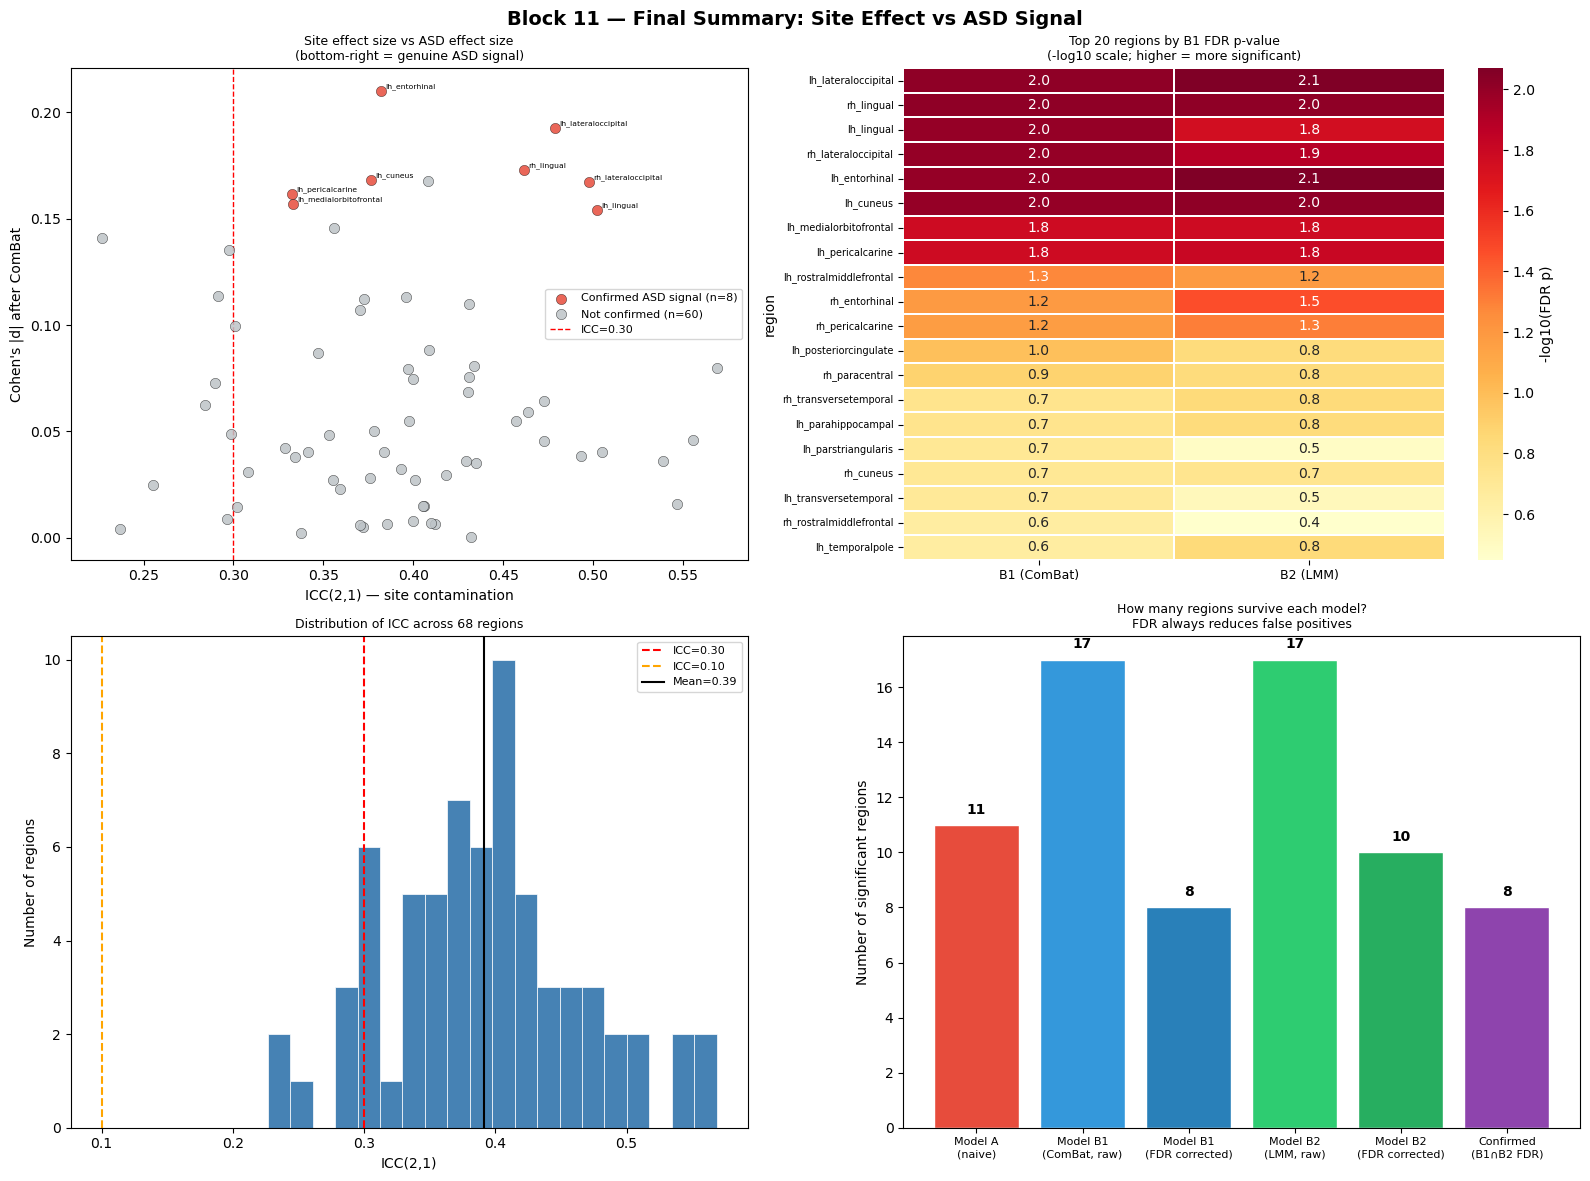

Block 11 complete.


In [20]:
# Final composite visualisation
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Block 11 — Final Summary: Site Effect vs ASD Signal', fontsize=14, fontweight='bold')

# --- Top-left: ICC vs |d_after|, coloured by final verdict ---
ax = axes[0, 0]
verdict_colors = {'Confirmed ASD signal': '#e74c3c', 'Not confirmed': '#bdc3c7'}
for verdict, color in verdict_colors.items():
    sub = df_summary[df_summary['final_verdict'] == verdict]
    ax.scatter(sub['ICC'], sub['d_after'].abs(),
               color=color, edgecolors='black', linewidth=0.3, s=55, alpha=0.85,
               label=f'{verdict} (n={len(sub)})', zorder=3)
ax.axvline(0.30, color='red', linestyle='--', linewidth=1, label='ICC=0.30')
ax.set_xlabel('ICC(2,1) — site contamination')
ax.set_ylabel("Cohen's |d| after ComBat")
ax.set_title('Site effect size vs ASD effect size\n(bottom-right = genuine ASD signal)', fontsize=9)
ax.legend(fontsize=8)
for _, row in df_summary[df_summary['final_verdict'] == 'Confirmed ASD signal'].iterrows():
    ax.annotate(row['region'], (row['ICC'], abs(row['d_after'])),
                fontsize=5.5, textcoords='offset points', xytext=(3, 2))

# --- Top-right: FDR p-values heatmap (top 20 most significant in B1) ---
ax = axes[0, 1]
top20 = df_summary.nsmallest(20, 'p_B1_fdr')[['region','p_B1_fdr','p_B2_fdr']].set_index('region')
sns.heatmap(-np.log10(top20.fillna(1) + 1e-10), annot=True, fmt='.1f',
            cmap='YlOrRd', ax=ax, linewidths=0.3,
            cbar_kws={'label': '-log10(FDR p)'})
ax.set_title('Top 20 regions by B1 FDR p-value\n(-log10 scale; higher = more significant)', fontsize=9)
ax.set_xticklabels(['B1 (ComBat)', 'B2 (LMM)'], fontsize=9)
ax.tick_params(axis='y', labelsize=7)

# --- Bottom-left: ICC distribution histogram ---
ax = axes[1, 0]
ax.hist(df_summary['ICC'], bins=20, color='steelblue', edgecolor='white', linewidth=0.5)
ax.axvline(0.30, color='red', linestyle='--', linewidth=1.5, label='ICC=0.30')
ax.axvline(0.10, color='orange', linestyle='--', linewidth=1.5, label='ICC=0.10')
ax.axvline(df_summary['ICC'].mean(), color='black', linestyle='-', linewidth=1.5,
           label=f'Mean={df_summary["ICC"].mean():.2f}')
ax.set_xlabel('ICC(2,1)')
ax.set_ylabel('Number of regions')
ax.set_title('Distribution of ICC across 68 regions', fontsize=9)
ax.legend(fontsize=8)

# --- Bottom-right: Model A vs B1 significant count bar chart ---
ax = axes[1, 1]
counts = {
    'Model A\n(naive)': df_summary['p_A'].apply(lambda p: p < 0.05).sum(),
    'Model B1\n(ComBat, raw)': df_summary['sig_B1_fdr'].sum() if False else df_compare['sig_B1'].sum(),
    'Model B1\n(FDR corrected)': df_summary['sig_B1_fdr'].sum(),
    'Model B2\n(LMM, raw)': df_compare['sig_B2'].sum(),
    'Model B2\n(FDR corrected)': df_summary['sig_B2_fdr'].sum(),
    'Confirmed\n(B1∩B2 FDR)': df_summary['sig_both_fdr'].sum()
}
bar_c = ['#e74c3c','#3498db','#2980b9','#2ecc71','#27ae60','#8e44ad']
bars = ax.bar(counts.keys(), counts.values(), color=bar_c, edgecolor='white')
for bar, val in zip(bars, counts.values()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            str(val), ha='center', va='bottom', fontsize=10, fontweight='bold')
ax.set_ylabel('Number of significant regions')
ax.set_title('How many regions survive each model?\nFDR always reduces false positives', fontsize=9)
ax.tick_params(axis='x', labelsize=8)

plt.tight_layout()
plt.savefig('block11_final_summary.png', dpi=120, bbox_inches='tight')
plt.show()
print('Block 11 complete.')

In [21]:
# ============================================================
# RQ1 FINAL ANSWER
# ============================================================
n_high_icc    = (df_summary['ICC'] > 0.30).sum()
n_high_eta    = (df_summary['eta2'] > 0.14).sum()
n_sig_A       = (df_summary['p_A'] < 0.05).sum()
n_sig_B1_raw  = df_compare['sig_B1'].sum()
n_sig_B2_raw  = df_compare['sig_B2'].sum()
n_fdr_B1      = df_summary['sig_B1_fdr'].sum()
n_fdr_B2      = df_summary['sig_B2_fdr'].sum()
n_confirmed   = df_summary['sig_both_fdr'].sum()
n_false_pos   = ((df_summary['p_A'] < 0.05) & ~df_summary['sig_B1_fdr'] & ~df_summary['sig_B2_fdr']).sum()

print('=' * 65)
print('RQ1 FINAL ANSWER')
print('=' * 65)
print(f'\nSITE EFFECT QUANTIFICATION')
print(f'  Regions with ICC > 0.30 (large site effect) : {n_high_icc}/68')
print(f'  Regions with η²  > 0.14 (large site effect) : {n_high_eta}/68')
print(f'  ICC and η² correlation                       : r={r:.2f}')

print(f'\nMODEL COMPARISON')
print(f'  Model A (naive, no site)          : {n_sig_A} significant regions')
print(f'  Model B1 (ComBat + OLS)           : {n_sig_B1_raw} before FDR | {n_fdr_B1} after FDR')
print(f'  Model B2 (Mixed-Effects LMM)      : {n_sig_B2_raw} before FDR | {n_fdr_B2} after FDR')
print(f'  Estimated false positives (A-only): {n_false_pos} regions')

print(f'\nASD SIGNAL')
print(f'  Confirmed by both B1 and B2 after FDR: {n_confirmed} regions')
if n_confirmed > 0:
    conf_regions = df_summary[df_summary['sig_both_fdr']]['region'].tolist()
    print(f'  These regions: {conf_regions}')
print()
print('CONCLUSION: Scanner/site differences did inflate apparent ASD effects.')
print(f'After harmonisation + FDR, {n_confirmed} region(s) show robust ASD signal.')
print('These form the basis for RQ2 and RQ4.')
print('=' * 65)

RQ1 FINAL ANSWER

SITE EFFECT QUANTIFICATION
  Regions with ICC > 0.30 (large site effect) : 59/68
  Regions with η²  > 0.14 (large site effect) : 68/68
  ICC and η² correlation                       : r=1.00

MODEL COMPARISON
  Model A (naive, no site)          : 11 significant regions
  Model B1 (ComBat + OLS)           : 17 before FDR | 8 after FDR
  Model B2 (Mixed-Effects LMM)      : 17 before FDR | 10 after FDR
  Estimated false positives (A-only): 3 regions

ASD SIGNAL
  Confirmed by both B1 and B2 after FDR: 8 regions
  These regions: ['lh_lingual', 'rh_lateraloccipital', 'lh_lateraloccipital', 'rh_lingual', 'lh_entorhinal', 'lh_cuneus', 'lh_medialorbitofrontal', 'lh_pericalcarine']

CONCLUSION: Scanner/site differences did inflate apparent ASD effects.
After harmonisation + FDR, 8 region(s) show robust ASD signal.
These form the basis for RQ2 and RQ4.


save

In [ ]:
# ============================================================
# SAVE HARMONISED DATASET
# ============================================================

# Save df_harmonised to CSV
# This avoids re-running ComBat (slow) in future sessions.
# All subsequent RQ analyses (RQ2, RQ3, RQ4) should load this file directly.

output_path = 'abide_harmonised_combat.csv'
df_harmonised.to_csv(output_path, index=False)

print(f'Saved: {output_path}')
print(f'Shape : {df_harmonised.shape}')
print(f'ASD   : {(df_harmonised.DX_GROUP == 1).sum()}')
print(f'Control: {(df_harmonised.DX_GROUP == 2).sum()}')
print(f'Sites  : {df_harmonised.SITE_ID.nunique()}')
print()

# Quick sanity check — site means should be aligned after ComBat
site_means = df_harmonised.groupby('SITE_ID')[THICKNESS_COLS].mean().mean(axis=1)
print('Mean thickness per site after ComBat (should be similar across sites):')
print(site_means.round(3).sort_values().to_string())

Saved: abide_harmonised.csv
Shape : (1027, 81)
ASD   : 499
Control: 528
Sites  : 20

Mean thickness per site after ComBat (should be similar across sites):
SITE_ID
SBL         2.522
CALTECH     2.613
CMU         2.629
MAX_MUN     2.644
USM         2.680
LEUVEN_1    2.682
PITT        2.732
TRINITY     2.758
OLIN        2.762
UM_2        2.770
NYU         2.781
SDSU        2.792
LEUVEN_2    2.798
UM_1        2.807
UCLA_1      2.809
UCLA_2      2.817
YALE        2.817
OHSU        2.842
STANFORD    2.852
KKI         2.853
